## Final Project

Requirements
1. Calibrate the stereo camera system and rectify the input images.

2. Then, for each sequence, do the following:
>- Compute disparity maps and reconstruct the 3D structure of the scene from the rectified stereo
image pairs.
>- Detect the Husky A200 robot in the scene by processing the input images.
>- Track the Husky A200 robot over time in 2D and 3D, including estimating its position during
complete occlusions
>- Include a dedicated Discussion and Limitations section at the end of the report, reflecting on the
overall approach, its limitations and failure cases, potential improvements, and possible directions
for future work. Discuss how you would improve or approach the problem differently given more
time or resources
3. Present the results in a short video demonstration showing the detection and tracking of the Husky
A200 robot across all four given sequences

Solution pipeline
- Calibration 
- Detection
- Position Estimation
- State Estimation

In [1]:
import numpy as np
import cv2 
import glob
import matplotlib.pyplot as plt

## Calibration

In [2]:
def calibration(left_imgs, right_imgs, chessboard_size, pattern_dist):
    # termination criteria
    criteria1 = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.001)
    # First we calibrate the two camera separately to get a more accurate calibration,
    # then we can calibrate the stereo pair to get the relative position of the two cameras
    # by passing the FIX_INTRINSIC_PARAM flag
    # We consider the left camera to be the first camera, as a convetion
    corners_left = []
    corners_right = []
    objpoints = []
    cols, rows = chessboard_size
    objpts = np.zeros((cols * rows, 3), np.float32)
    objpts[:, :2] = np.mgrid[0:cols, 0:rows].T.reshape(-1, 2) * pattern_dist

    h, w = left_imgs[0].shape[:2]
    
    for i in range(len(left_imgs)):
        imgl = left_imgs[i]
        imgr = right_imgs[i]
        ret1, cl = cv2.findChessboardCorners(imgl, chessboard_size, flags=cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE + cv2.CALIB_CB_FAST_CHECK)
        ret2, cr = cv2.findChessboardCorners(imgr, chessboard_size, flags=cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE + cv2.CALIB_CB_FAST_CHECK)
        # Only append the corners if both images have detected the chessboard. The corners will then be used for stereo calibration
        # so we need to make sure that both images have detected the chessboard
        if ret1 and ret2:
            # refine detected corners
            # A first trial without refining the corners gave a mean reprojection error of 0.89 pixels
            # while the first trial with refining the corners gave a mean reprojection error of 0.3 and 0.2 pixels
            # The problem with this refinement is that the size of the chessboard is different between images,
            # so the window search dimensions differ between images. Since when the chessboard is far away,
            #  the corners are very close to each other, the window search dimensions are too big and the refinement fails.
            # Because of this we choose a smaller window size, but more iterations
            corners_left.append(cv2.cornerSubPix(imgl, cl, (9,9), (-1,-1), criteria1))
            corners_right.append(cv2.cornerSubPix(imgr, cr, (9,9), (-1,-1), criteria1))
            objpoints.append(objpts)
    
            # Draw and display the corners on the left images
            #img1 = cv2.cvtColor(imgl.copy(), cv2.COLOR_GRAY2RGB)
            #cv2.drawChessboardCorners(img1, chessboard_size, corners_left[-1], ret1)
            #cv2.imshow('img', img1)
            #key = cv2.waitKey(1) & 0xFF
            #cv2.waitKey(30)
            #if key == ord('q'): 
            #    break
    cv2.destroyAllWindows()
            
    
    # Calibrate the two cameras separately. Pass only the corners that were detected in both images to the calibration function
    ret1, mtx1, dist1, rvecs1, tvecs1 = cv2.calibrateCamera(objpoints, corners_left, (w,h), None, None)
    ret2, mtx2, dist2, rvecs2, tvecs2 = cv2.calibrateCamera(objpoints, corners_right, (w,h), None, None)
    print("Left Camera matrix (K):\n", mtx1)
    print("Right Camera matrix (K):\n", mtx2)
    print("Left Distortion coefficients:\n", dist1.ravel())
    print("Right Distortion coefficients:\n", dist2.ravel())

    # Calculate reprojection errors
    total_error = 0
    total_error2 = 0

    for i in range(len(objpoints)):
        projected, _ = cv2.projectPoints(objpoints[i], rvecs1[i], tvecs1[i], mtx1, dist1)
        pts_real = corners_left[i].reshape(-1, 2)
        pts_proj = projected.reshape(-1, 2)
        error = np.mean(np.linalg.norm(pts_real - pts_proj, axis=1))
        total_error += error

        projected2, _ = cv2.projectPoints(objpoints[i], rvecs2[i], tvecs2[i], mtx2, dist2)
        pts_real2 = corners_right[i].reshape(-1, 2)
        pts_proj2 = projected2.reshape(-1, 2)
        error2 = np.mean(np.linalg.norm(pts_real2 - pts_proj2, axis=1))
        total_error2 += error2 

    print(f"Mean left reprojection error: {total_error / len(objpoints):.4f} pixels")
    print(f"Mean right reprojection error: {total_error2 / len(objpoints):.4f} pixels")

    retval, _, _, _, _, R, T, E, F = cv2.stereoCalibrate(
        objpoints, corners_left, corners_right, 
        mtx1, dist1, mtx2, dist2, 
        (w,h), flags=cv2.CALIB_FIX_INTRINSIC
    )

    return mtx1, mtx2, dist1, dist2,R, T, E, F

def make_rectify_maps(mtx1, mtx2, dist1, dist2, image_size, R, T, alpha = 0):
    # Compute rectification transforms once, from calibration results only
    R1, R2, P1, P2, Q, roi1, roi2 = cv2.stereoRectify(
        mtx1, dist1, mtx2, dist2, image_size, R, T,
        flags=cv2.CALIB_ZERO_DISPARITY, alpha=alpha)

    maps_left = cv2.initUndistortRectifyMap(mtx1, dist1, R1, P1, image_size, cv2.CV_32FC1)
    maps_right = cv2.initUndistortRectifyMap(mtx2, dist2, R2, P2, image_size, cv2.CV_32FC1)

    # Common valid region, so both outputs have the same size and content
    x1, y1, w1, h1 = roi1
    x2, y2, w2, h2 = roi2
    crop = (max(x1, x2), max(y1, y2),
            min(x1 + w1, x2 + w2), min(y1 + h1, y2 + h2))

    return maps_left, maps_right, crop, Q

# pass roi if you want to crop the images to the valid pixels after undistortion. 
def unidistort_rectify(left_imgs, right_imgs, maps_left, maps_right, crop=None):
    h, w = left_imgs[0].shape[:2]
    (ml1, ml2) = maps_left
    (mr1, mr2) = maps_right
    left = []
    right = []
    for imgl, imgr in zip(left_imgs, right_imgs):
        # Undistort the images using the camera matrices and distortion coefficients
        ur_left = cv2.remap(imgl, ml1, ml2, cv2.INTER_LINEAR)
        ur_right = cv2.remap(imgr, mr1, mr2, cv2.INTER_LINEAR)

        # It is sufficient to set alpha = 0 or alpha = 1 based on if we want to crop the images or not
        if crop is not None:
           # Crop the images to the valid pixels after undistortion
            ur_left = ur_left[crop]
            ur_right = ur_right[crop]
        left.append(ur_left)
        right.append(ur_right)

    return left, right

left_imgs_pth = glob.glob("0_calib/left/*.png")
right_imgs_pth = glob.glob("0_calib/right/*.png")
chessboard_size = (7, 5)  # Number of inner corners per a chessboard row and column

# in millimeters
pattern_dist = 80

# Sort the image paths to ensure they are in the correct order
left_imgs_pth.sort()
right_imgs_pth.sort()

left_imgs = []
right_imgs = []
for left_img_path, right_img_path in zip(left_imgs_pth, right_imgs_pth):
    left_imgs.append(cv2.cvtColor(cv2.imread(left_img_path), cv2.COLOR_BGR2GRAY))
    right_imgs.append(cv2.cvtColor(cv2.imread(right_img_path), cv2.COLOR_BGR2GRAY))

# Perform calibration using the images
mtx1, mtx2, dist1, dist2, R, T, E, F = calibration(left_imgs, right_imgs, chessboard_size, pattern_dist)

# test undistortion and rectification on the calibration images
maps_left, maps_right, crop, Q = make_rectify_maps(mtx1, mtx2, dist1, dist2, left_imgs[0].shape[::-1], R, T)

ul, ur = unidistort_rectify(left_imgs[0:2], right_imgs[0:2], maps_left, maps_right)


Left Camera matrix (K):
 [[614.39790861   0.         678.51189566]
 [  0.         614.37759457 390.4007832 ]
 [  0.           0.           1.        ]]
Right Camera matrix (K):
 [[603.56783133   0.         662.30219844]
 [  0.         603.55549566 392.69659562]
 [  0.           0.           1.        ]]
Left Distortion coefficients:
 [-0.04881689  0.06596942  0.00746363  0.00501252 -0.04554361]
Right Distortion coefficients:
 [-0.08187327  0.08508145  0.00219752  0.00343575 -0.03758563]
Mean left reprojection error: 0.3057 pixels
Mean right reprojection error: 0.1781 pixels


Text(0.5, 1.0, 'Right image')

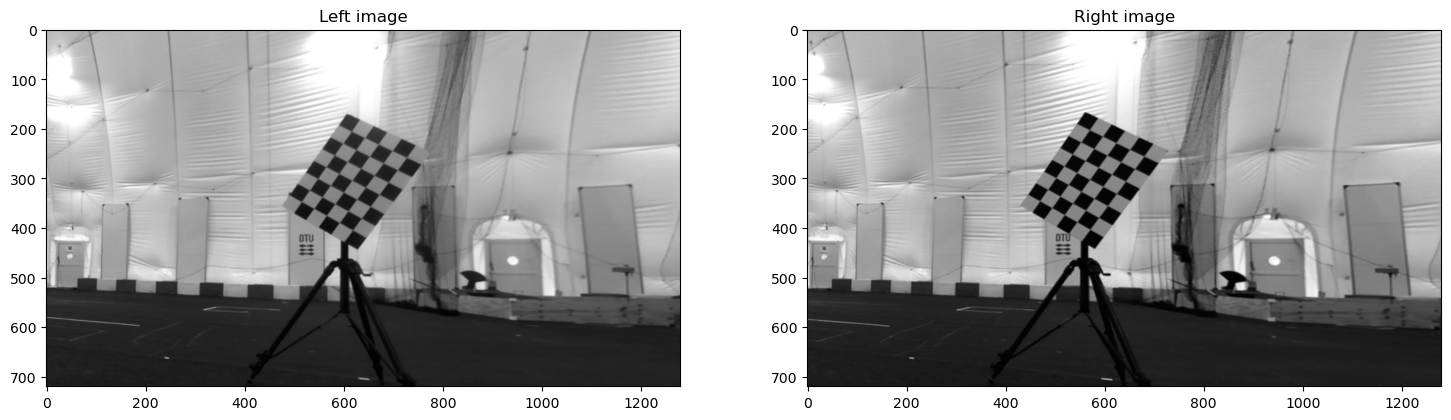

In [3]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 18))
ax[0].imshow(cv2.cvtColor(ul[0], cv2.COLOR_GRAY2RGB))
ax[0].set_title("Left image")
ax[1].imshow(cv2.cvtColor(ur[0], cv2.COLOR_GRAY2RGB))
ax[1].set_title("Right image")


Text(0.5, 1.0, 'Undistorted and rectified image')

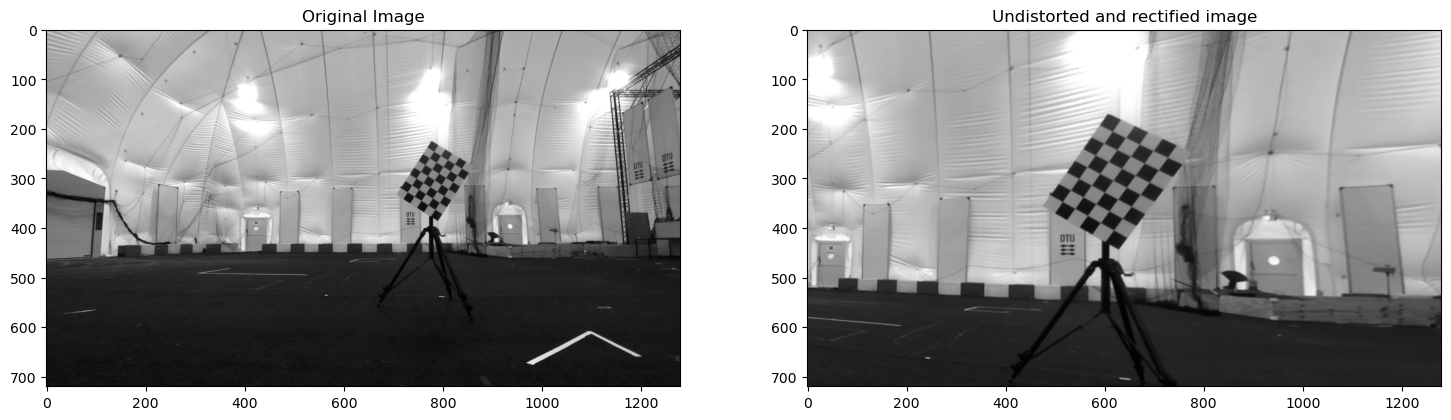

In [4]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 18))
ax[0].imshow(cv2.cvtColor(left_imgs[0], cv2.COLOR_GRAY2RGB))
ax[0].set_title("Original Image")
ax[1].imshow(cv2.cvtColor(ul[0], cv2.COLOR_GRAY2RGB))
ax[1].set_title("Undistorted and rectified image")

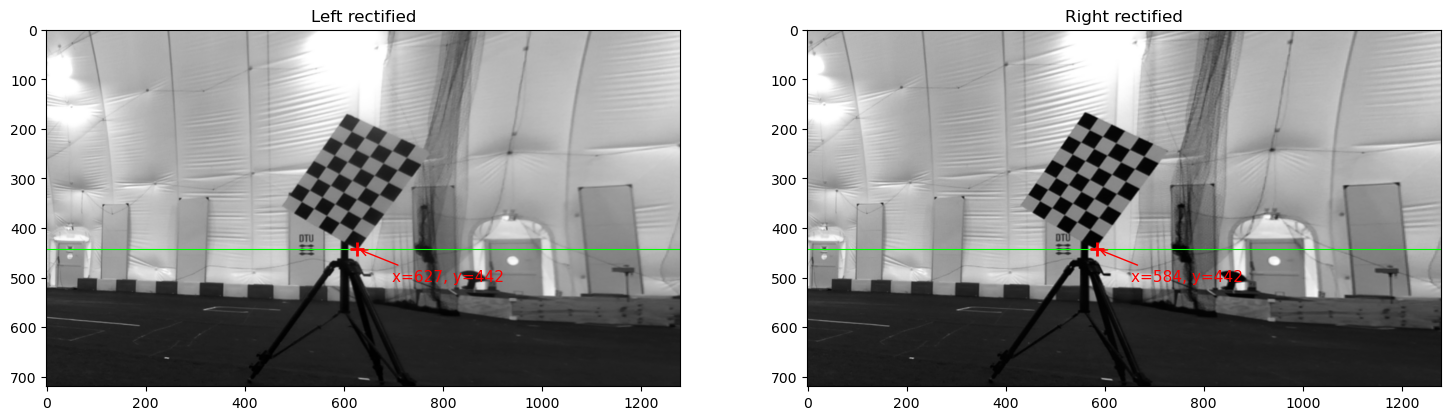

In [5]:
y = 442     # same row for both images
xl = 627    # column of the corner in the left rectified image
xr = 584    # column of the same corner in the right rectified image (xl - disparity)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 8))

for a, img, x, name in [(ax[0], ul[0], xl, "Left rectified"),
                        (ax[1], ur[0], xr, "Right rectified")]:
    a.imshow(img, cmap="gray")
    a.axhline(y, color="lime", linewidth=0.8)          # same row in both panels
    a.plot(x, y, "r+", markersize=10, markeredgewidth=2)
    a.annotate(f"x={x}, y={y}\n", (x, y),
               xytext=(x + 70, y + 100), color="red", fontsize=11,
               arrowprops=dict(arrowstyle="->", color="red"))
    a.set_title(name)

plt.show()

## Detection

In [6]:
def detection():
    return

## 3D Position Estimation

In [7]:
def position():
    return

## State Estimation

In [8]:
class KF():
    def __init__ (self):
        return
    
    def predict(self):
        return

    def update(self):
        return

### Datasets
- Dataset 1

In [9]:
"""
Test with dataset 2
"""


'\nTest with dataset 2\n'

- Dataset 2

In [10]:
"""
Test with dataset 2
"""

'\nTest with dataset 2\n'

- Dataset 3

In [11]:
"""
Test with dataset 3
"""

'\nTest with dataset 3\n'

- Dataset 4

In [12]:
"""
Test with dataset 4
"""

'\nTest with dataset 4\n'